In [ ]:
# importing libraries
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

In [ ]:
# loading the dataset
df = pd.read_csv(r"G:\datamites\new project\customer-segmentation-retention-analysis\online_retail_II.csv\online_retail_II.csv")

## statistical summary

In [4]:
df.head()

,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country
0,489434,85048,15CM CHRISTMAS GLASS BALL 20 LIGHTS,12,2009-12-01 07:45:00,6.95,13085.0,United Kingdom
1,489434,79323P,PINK CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085.0,United Kingdom
2,489434,79323W,WHITE CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085.0,United Kingdom
3,489434,22041,"RECORD FRAME 7"" SINGLE SIZE",48,2009-12-01 07:45:00,2.10,13085.0,United Kingdom
4,489434,21232,STRAWBERRY CERAMIC TRINKET BOX,24,2009-12-01 07:45:00,1.25,13085.0,United Kingdom


In [5]:
df.tail()

,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country
1067366,581587,22899,CHILDREN'S APRON DOLLY GIRL,6,2011-12-09 12:50:00,2.10,12680.0,France
1067367,581587,23254,CHILDRENS CUTLERY DOLLY GIRL,4,2011-12-09 12:50:00,4.15,12680.0,France
1067368,581587,23255,CHILDRENS CUTLERY CIRCUS PARADE,4,2011-12-09 12:50:00,4.15,12680.0,France
1067369,581587,22138,BAKING SET 9 PIECE RETROSPOT,3,2011-12-09 12:50:00,4.95,12680.0,France
1067370,581587,POST,POSTAGE,1,2011-12-09 12:50:00,18.00,12680.0,France


In [7]:
df.shape

(1067371, 8)

In [6]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1067371 entries, 0 to 1067370
Data columns (total 8 columns):
 #   Column       Non-Null Count    Dtype  
---  ------       --------------    -----  
 0   Invoice      1067371 non-null  str    
 1   StockCode    1067371 non-null  str    
 2   Description  1062989 non-null  str    
 3   Quantity     1067371 non-null  int64  
 4   InvoiceDate  1067371 non-null  str    
 5   Price        1067371 non-null  float64
 6   Customer ID  824364 non-null   float64
 7   Country      1067371 non-null  str    
dtypes: float64(2), int64(1), str(5)
memory usage: 65.1 MB


In [8]:
df.describe(include="O")

C:\Users\sahil\AppData\Local\Temp\ipykernel_20464\504318277.py:1: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  df.describe(include="O")


,Invoice,StockCode,Description,InvoiceDate,Country
count,1067371,1067371,1062989,1067371,1067371
unique,53628,5305,5698,47635,43
top,537434,85123A,WHITE HANGING HEART T-LIGHT HOLDER,2010-12-06 16:57:00,United Kingdom
freq,1350,5829,5918,1350,981330


In [9]:
df.describe()

,Quantity,Price,Customer ID
count,1.067371e+06,1.067371e+06,824364.000000
mean,9.938898e+00,4.649388e+00,15324.638504
std,1.727058e+02,1.235531e+02,1697.464450
min,-8.099500e+04,-5.359436e+04,12346.000000
25%,1.000000e+00,1.250000e+00,13975.000000
50%,3.000000e+00,2.100000e+00,15255.000000
75%,1.000000e+01,4.150000e+00,16797.000000
max,8.099500e+04,3.897000e+04,18287.000000


In [10]:
df.isnull().sum()

Invoice             0
StockCode           0
Description      4382
Quantity            0
InvoiceDate         0
Price               0
Customer ID    243007
Country             0
dtype: int64

In [15]:
df.duplicated().sum()

np.int64(34335)

In [14]:
df[df.duplicated(keep=False)]

,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country
362,489517,21913,VINTAGE SEASIDE JIGSAW PUZZLES,1,2009-12-01 11:34:00,3.75,16329.0,United Kingdom
363,489517,21912,VINTAGE SNAKES & LADDERS,1,2009-12-01 11:34:00,3.75,16329.0,United Kingdom
365,489517,21821,GLITTER STAR GARLAND WITH BELLS,1,2009-12-01 11:34:00,3.75,16329.0,United Kingdom
367,489517,22319,HAIRCLIPS FORTIES FABRIC ASSORTED,12,2009-12-01 11:34:00,0.65,16329.0,United Kingdom
368,489517,22130,PARTY CONE CHRISTMAS DECORATION,6,2009-12-01 11:34:00,0.85,16329.0,United Kingdom
...,...,...,...,...,...,...,...,...
1067136,581538,22068,BLACK PIRATE TREASURE CHEST,1,2011-12-09 11:34:00,0.39,14446.0,United Kingdom
1067150,581538,23318,BOX OF 6 MINI VINTAGE CRACKERS,1,2011-12-09 11:34:00,2.49,14446.0,United Kingdom
1067153,581538,22992,REVOLVER WOODEN RULER,1,2011-12-09 11:34:00,1.95,14446.0,United Kingdom
1067160,581538,22694,WICKER STAR,1,2011-12-09 11:34:00,2.10,14446.0,United Kingdom


In [16]:
for col in df.columns:
    print(f"{col} : {df[col].duplicated().sum()} duplicated values")

Invoice : 1013743 duplicated values
StockCode : 1062066 duplicated values
Description : 1061672 duplicated values
Quantity : 1066314 duplicated values
InvoiceDate : 1019736 duplicated values
Price : 1064564 duplicated values
Customer ID : 1061428 duplicated values
Country : 1067328 duplicated values


## Exploratory Data Analysis

In [19]:
df.Country.nunique()

43

In [25]:
df.Country.unique()

<StringArray>
[      'United Kingdom',               'France',                  'USA',
              'Belgium',            'Australia',                 'EIRE',
              'Germany',             'Portugal',                'Japan',
              'Denmark',              'Nigeria',          'Netherlands',
               'Poland',                'Spain',      'Channel Islands',
                'Italy',               'Cyprus',               'Greece',
               'Norway',              'Austria',               'Sweden',
 'United Arab Emirates',              'Finland',          'Switzerland',
          'Unspecified',                'Malta',              'Bahrain',
                  'RSA',              'Bermuda',            'Hong Kong',
            'Singapore',             'Thailand',               'Israel',
            'Lithuania',          'West Indies',              'Lebanon',
                'Korea',               'Brazil',               'Canada',
              'Iceland',         'Sau

In [23]:
df.Country.value_counts()

Country
United Kingdom          981330
EIRE                     17866
Germany                  17624
France                   14330
Netherlands               5140
Spain                     3811
Switzerland               3189
Belgium                   3123
Portugal                  2620
Australia                 1913
Channel Islands           1664
Italy                     1534
Norway                    1455
Sweden                    1364
Cyprus                    1176
Finland                   1049
Austria                    938
Denmark                    817
Unspecified                756
Greece                     663
Japan                      582
USA                        535
Poland                     535
United Arab Emirates       500
Israel                     371
Hong Kong                  364
Singapore                  346
Malta                      299
Iceland                    253
Canada                     228
Lithuania                  189
RSA                        169


In [ ]:
# the percentage of transactions in each country
country_percentage = (
    df['Country']
    .value_counts(normalize=True)
    .mul(100)
    .round(2)
    .reset_index()
)

country_percentage.columns = ['Country', 'Percentage (%)']

country_percentage

,Country,Percentage (%)
0,United Kingdom,91.94
1,EIRE,1.67
2,Germany,1.65
3,France,1.34
4,Netherlands,0.48
5,Spain,0.36
6,Switzerland,0.30
7,Belgium,0.29
8,Portugal,0.25
9,Australia,0.18


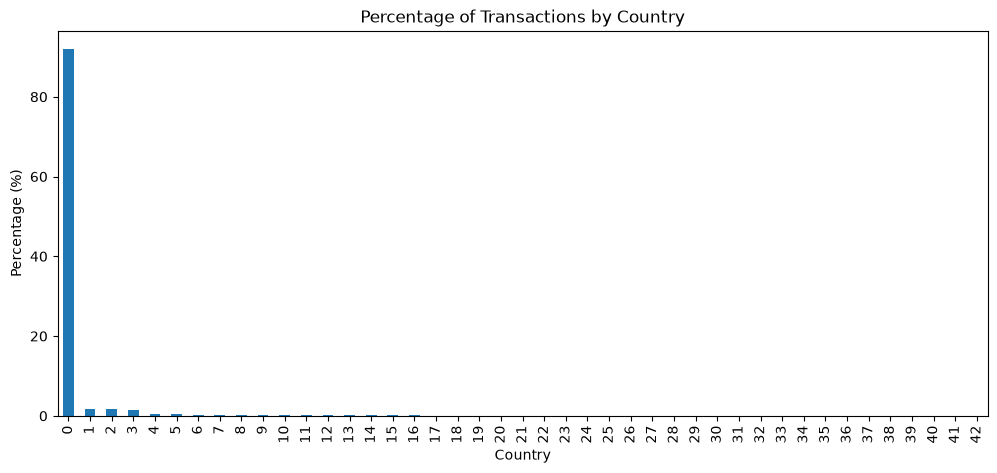

In [29]:
country_percentage['Percentage (%)'].plot(kind='bar', figsize=(12,5))
plt.title('Percentage of Transactions by Country')
plt.xlabel(df['Country'].name)
plt.ylabel('Percentage (%)')
plt.xticks(rotation=90)
plt.show()

### Most of the transaction is from United Kingdom which is around 91 % and other transactions are mostly made by the neighboring countries like Ireland, Germany and France.

In [ ]:
#  the transaction period

df['InvoiceDate'] = pd.to_datetime(df['InvoiceDate'])

print(f"Data ranges from {df['InvoiceDate'].min()} to {df['InvoiceDate'].max()}")

Data ranges from 2009-12-01 07:45:00 to 2011-12-09 12:50:00


In [32]:
print(f"Number of transactions regestered : {df['Invoice'].nunique()}")

Number of transactions regestered : 53628


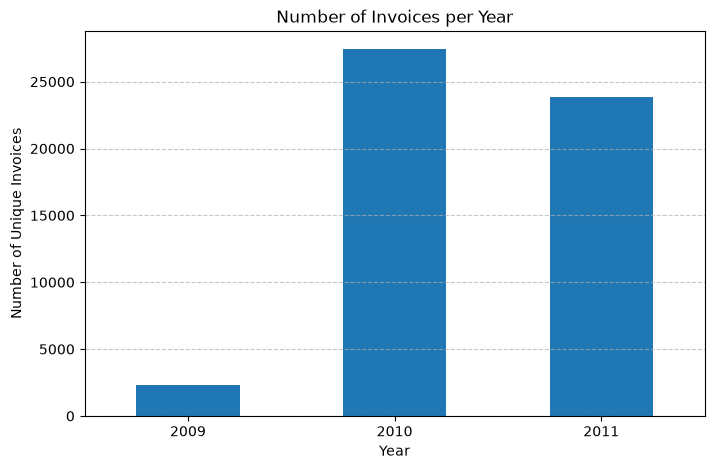

In [33]:
# Convert InvoiceDate to datetime
df['InvoiceDate'] = pd.to_datetime(df['InvoiceDate'])

# Extract year
df['Year'] = df['InvoiceDate'].dt.year

# Count unique invoices per year
invoice_per_year = df.groupby('Year')['Invoice'].nunique()

# Plot
plt.figure(figsize=(8,5))
invoice_per_year.plot(kind='bar')

plt.title('Number of Invoices per Year')
plt.xlabel('Year')
plt.ylabel('Number of Unique Invoices')
plt.xticks(rotation=0)
plt.grid(axis='y', linestyle='--', alpha=0.7)

plt.show()

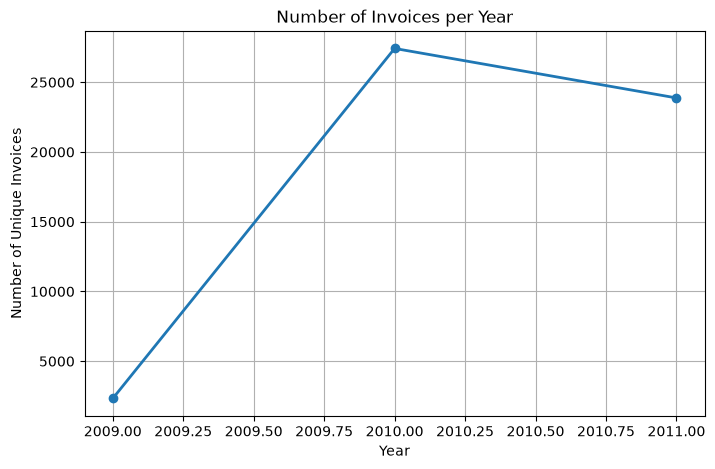

In [34]:
plt.figure(figsize=(8,5))

plt.plot(invoice_per_year.index,
         invoice_per_year.values,
         marker='o',
         linewidth=2)

plt.title('Number of Invoices per Year')
plt.xlabel('Year')
plt.ylabel('Number of Unique Invoices')
plt.grid(True)

plt.show()